In [24]:
import numpy
import pandas
import matplotlib
import sklearn

print("Da co du 4 thu vien")

import numpy, pandas, matplotlib, sklearn

print("numpy ", numpy.__version__)
print("pandas ", pandas.__version__)
print("matplotlib ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)

import sklearn
import pandas as pd
import os

print(os.listdir())

df = pd.read_csv("/content/gia_nha.csv")
print(df)

print("Kích thước bảng:", df.shape)
print()

print("Nam dong dau tien:")
print(df.head())
print()

print("Ten cac cot:", list(df.columns))
print()

print("Thong ke nhanh cot dien_tich va cot gia:")
print(df[["dien_tich", "gia"]].describe().round(2))
print()

print("So o bi thieu trong tung cot:")
print(df.isna().sum())

Da co du 4 thu vien
numpy  2.1.3
pandas  2.2.3
matplotlib  3.10.0
scikit-learn 1.6.1
['.config', 'gia_nha.csv', 'bai2.png', 'gia_nha (1).csv', 'sample_data']
    dien_tich  so_phong  tuoi_nha   gia
0        35.5         1        18  3.00
1        37.6         2         7  3.87
2        49.4         2        20  4.25
3        49.0         2        16  4.60
4        49.9         1        12  3.99
5        50.4         1        19  4.24
6        51.1         2        17  4.60
7        53.1         2         2  5.08
8        55.9         2         5  4.96
9        56.5         2        17  4.88
10       58.9         2        10  5.46
11       58.9         2         8  4.85
12       60.7         2        14  5.16
13       59.6         1         4  5.14
14       61.3         2        25  4.56
15       66.5         2        14  5.32
16       63.6         1         0  4.98
17       66.5         2        12  5.22
18       66.6         3        19  5.13
19       66.3         2        15  5.27
20

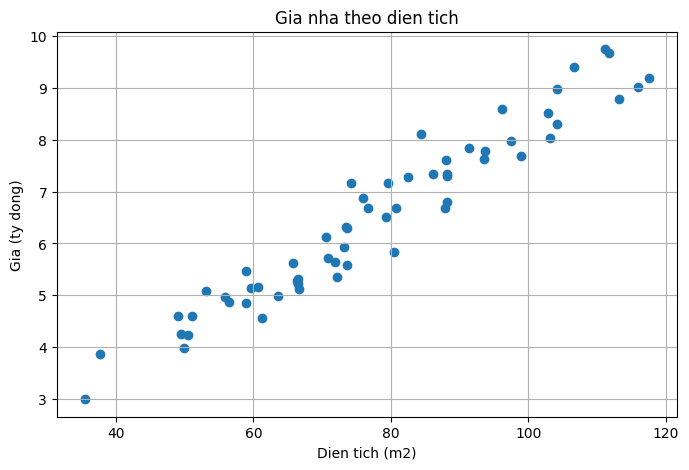

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(df["dien_tich"], df["gia"])

plt.xlabel("Dien tich (m2)")
plt.ylabel("Gia (ty dong)")
plt.title("Gia nha theo dien tich")

plt.grid(True)
plt.show()

In [26]:
import pandas as pd

df = pd.read_csv("/content/gia_nha.csv")

nho = df.iloc[[0, 14, 29, 44, 59]]

x = nho["dien_tich"].to_numpy()
y = nho["gia"].to_numpy()

def mse(w, b):
    y_du_doan = w * x + b
    sai_so = y - y_du_doan
    return (sai_so ** 2).mean()

print("Nam can duoc chon:")
for i in range(5):
    print(f" {x[i]:6.1f} m2 -> {y[i]:5.2f} ty")

print()

for w, b in [(0.05, 1.5), (0.08, 0.5)]:
    print(f"Duong thang y = {w} * x + {b}")

    for i in range(5):
        du_doan = w * x[i] + b
        sai_so = y[i] - du_doan
        print(f" x = {x[i]:6.1f} that = {y[i]:5.2f}"
              f" du doan = {du_doan:5.2f} sai so = {sai_so:+6.2f}")

    print(f" MSE = {mse(w, b):.4f}")
    print()

print("Duong nao co MSE nho hon thi duong do khop du lieu tot hon.")

Nam can duoc chon:
   35.5 m2 ->  3.00 ty
   61.3 m2 ->  4.56 ty
   74.2 m2 ->  7.17 ty
   91.3 m2 ->  7.83 ty
  115.9 m2 ->  9.01 ty

Duong thang y = 0.05 * x + 1.5
 x =   35.5 that =  3.00 du doan =  3.28 sai so =  -0.28
 x =   61.3 that =  4.56 du doan =  4.56 sai so =  -0.00
 x =   74.2 that =  7.17 du doan =  5.21 sai so =  +1.96
 x =   91.3 that =  7.83 du doan =  6.07 sai so =  +1.76
 x =  115.9 that =  9.01 du doan =  7.30 sai so =  +1.71
 MSE = 1.9947

Duong thang y = 0.08 * x + 0.5
 x =   35.5 that =  3.00 du doan =  3.34 sai so =  -0.34
 x =   61.3 that =  4.56 du doan =  5.40 sai so =  -0.84
 x =   74.2 that =  7.17 du doan =  6.44 sai so =  +0.73
 x =   91.3 that =  7.83 du doan =  7.80 sai so =  +0.03
 x =  115.9 that =  9.01 du doan =  9.77 sai so =  -0.76
 MSE = 0.3896

Duong nao co MSE nho hon thi duong do khop du lieu tot hon.


In [27]:
import numpy as np
import pandas as pd

df = pd.read_csv("/content/gia_nha.csv")

x = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

x_tb = x.mean()
y_tb = y.mean()

# Công thức bình phương tối thiểu cho đường thẳng một biến
tu_so = ((x - x_tb) * (y - y_tb)).sum()
mau_so = ((x - x_tb) ** 2).sum()

w = tu_so / mau_so
b = y_tb - w * x_tb

print(f"Trung binh dien tich : {x_tb:.4f}")
print(f"Trung binh gia : {y_tb:.4f}")
print(f"Tu so : {tu_so:.4f}")
print(f"Mau so : {mau_so:.4f}")
print()

print(f"He so goc w = {w:.6f}")
print(f"He so chan b = {b:.6f}")
print()

print(f"Mo hinh: gia = {w:.4f} * dien_tich + {b:.4f}")
print()

y_du_doan = w * x + b
mse = ((y - y_du_doan) ** 2).mean()

print(f"MSE tren toan bo 60 can: {mse:.4f}")

# Dự đoán cho một căn 80 m2
print(f"Can 80 m2 duoc du doan: {w * 80 + b:.3f} ty dong")

Trung binh dien tich : 77.7317
Trung binh gia : 6.4933
Tu so : 1890.2297
Mau so : 24120.2898

He so goc w = 0.078367
He so chan b = 0.401752

Mo hinh: gia = 0.0784 * dien_tich + 0.4018

MSE tren toan bo 60 can: 0.1790
Can 80 m2 duoc du doan: 6.671 ty dong


In [28]:
import pandas as pd
from sklearn.linear_model import LinearRegression

df = pd.read_csv("/content/gia_nha.csv")

# X phải là bảng hai chiều, y là dãy một chiều
X = df[["dien_tich"]]
y = df["gia"]

mo_hinh = LinearRegression()
mo_hinh.fit(X, y)

print("He so goc w =", round(float(mo_hinh.coef_[0]), 6))
print("He so chan b =", round(float(mo_hinh.intercept_), 6))
print()

print("Ket qua tinh tay o buoc 3: w = 0.078367, b = 0.401752")
print()

can_moi = pd.DataFrame({"dien_tich": [80.0, 100.0]})
du_doan = mo_hinh.predict(can_moi)

for dt, gia in zip(can_moi["dien_tich"], du_doan):
    print(f"Can {dt:.0f} m2 -> du doan {gia:.3f} ty dong")

He so goc w = 0.078367
He so chan b = 0.401752

Ket qua tinh tay o buoc 3: w = 0.078367, b = 0.401752

Can 80 m2 -> du doan 6.671 ty dong
Can 100 m2 -> du doan 8.238 ty dong


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# X và y đã có từ phần 5.2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("So can trong tap hoc:", len(X_train))
print("So can trong tap kiem tra:", len(X_test))

# Tạo và huấn luyện mô hình trên tập học
mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)

print()
print("He so goc w =", round(float(mo_hinh.coef_[0]), 6))
print("He so chan b =", round(float(mo_hinh.intercept_), 6))

So can trong tap hoc: 48
So can trong tap kiem tra: 12

He so goc w = 0.077837
He so chan b = 0.454717


In [30]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("/content/gia_nha.csv")

X = df[["dien_tich"]]
y = df["gia"]

# 80% để học, 20% để kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("So can de hoc :", len(X_train))
print("So can de kiem tra:", len(X_test))
print()

mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)

y_pred = mo_hinh.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE = {mae:.4f} ty dong")
print(f"MSE = {mse:.4f}")
print(f"RMSE = {rmse:.4f} ty dong")
print(f"R2 = {r2:.4f}")
print()

print("Mot vai can trong tap kiem tra:")

for dt, that, du_doan in list(
    zip(X_test["dien_tich"], y_test, y_pred)
)[:5]:
    print(
        f" {dt:6.1f} m2 that = {that:5.2f} "
        f"du doan = {du_doan:5.2f}"
        f" sai so = {that - du_doan:+5.2f}"
    )

So can de hoc : 48
So can de kiem tra: 12

MAE = 0.2578 ty dong
MSE = 0.1392
RMSE = 0.3730 ty dong
R2 = 0.9622

Mot vai can trong tap kiem tra:
   35.5 m2 that =  3.00 du doan =  3.22 sai so = -0.22
   50.4 m2 that =  4.24 du doan =  4.38 sai so = -0.14
   82.5 m2 that =  7.28 du doan =  6.88 sai so = +0.40
   93.6 m2 that =  7.63 du doan =  7.74 sai so = -0.11
   59.6 m2 that =  5.14 du doan =  5.09 sai so = +0.05


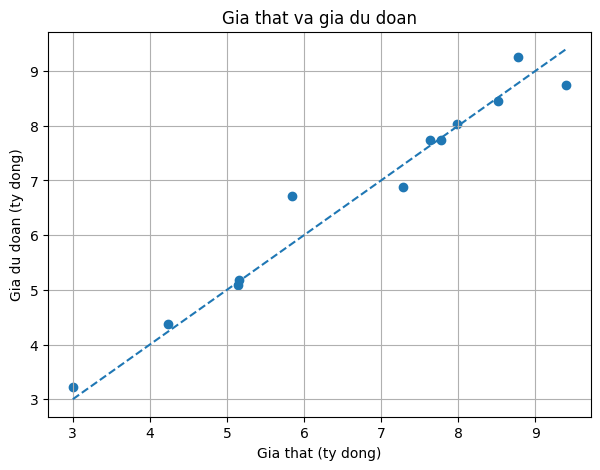

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Gia that (ty dong)")
plt.ylabel("Gia du doan (ty dong)")
plt.title("Gia that va gia du doan")

plt.grid(True)
plt.show()

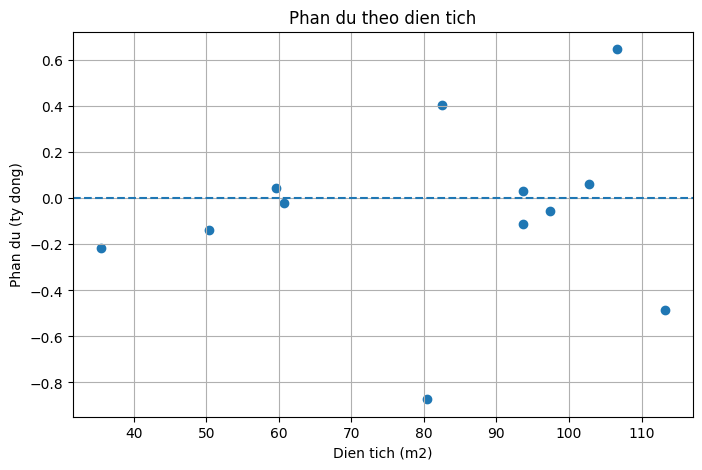

In [32]:
du = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(X_test["dien_tich"], du)

plt.axhline(0, linestyle="--")

plt.xlabel("Dien tich (m2)")
plt.ylabel("Phan du (ty dong)")
plt.title("Phan du theo dien tich")

plt.grid(True)
plt.show()

In [33]:
import numpy as np
import pandas as pd

df = pd.read_csv("/content/gia_nha.csv")

x_goc = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

# Đưa diện tích về thang đo nhỏ quanh số 0
x_tb = x_goc.mean()
x_do_lech = x_goc.std()
x = (x_goc - x_tb) / x_do_lech

w, b = 0.0, 0.0
toc_do_hoc = 0.1
so_vong = 200
n = len(x)

print("Vong w b MSE")

for vong in range(1, so_vong + 1):
    y_du_doan = w * x + b

    # Dự đoán trừ giá thật
    chenh_lech = y_du_doan - y

    # Độ dốc của MSE theo w và b
    grad_w = (2 / n) * (chenh_lech * x).sum()
    grad_b = (2 / n) * chenh_lech.sum()

    # Cập nhật w và b
    w -= toc_do_hoc * grad_w
    b -= toc_do_hoc * grad_b

    if vong in (1, 2, 5, 10, 25, 50, 100, 200):
        mse = (((w * x + b) - y) ** 2).mean()
        print(f"{vong:4d} {w:7.4f} {b:7.4f} {mse:8.4f}")

print()

# Đổi w và b về lại thang đo mét vuông ban đầu
w_goc = w / x_do_lech
b_goc = b - w * x_tb / x_do_lech

print("Sau khi doi ve thang do met vuong:")
print(f" w = {w_goc:.6f}")
print(f" b = {b_goc:.6f}")
print("So voi cong thuc o buoc 3: w = 0.078367, b = 0.401752")

Vong w b MSE
   1  0.3143  1.2987  28.7437
   2  0.5657  2.3376  18.4604
   5  1.0564  4.3656   4.9714
  10  1.4025  5.7961   0.6936
  25  1.5653  6.4688   0.1797
  50  1.5712  6.4932   0.1790
 100  1.5713  6.4933   0.1790
 200  1.5713  6.4933   0.1790

Sau khi doi ve thang do met vuong:
 w = 0.078367
 b = 0.401752
So voi cong thuc o buoc 3: w = 0.078367, b = 0.401752


In [34]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("/content/gia_nha.csv")

y = df["gia"]

# Mô hình 1 biến
X_mot = df[["dien_tich"]]

# Mô hình 3 biến
X_ba = df[["dien_tich", "so_phong", "tuoi_nha"]]

for ten, X in [("Mot bien ", X_mot), ("Ba bien ", X_ba)]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    mo_hinh = LinearRegression()
    mo_hinh.fit(X_train, y_train)

    r2 = r2_score(y_test, mo_hinh.predict(X_test))

    print(f"{ten}: R2 tren tap kiem tra = {r2:.4f}")

print()

# Xem các hệ số của mô hình 3 biến
X_train, X_test, y_train, y_test = train_test_split(
    X_ba, y, test_size=0.2, random_state=42
)

mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)

print("He so cua tung bien:")

for ten_cot, he_so in zip(X_ba.columns, mo_hinh.coef_):
    print(f" {ten_cot:12s} {he_so:+.4f}")

print(f" {'he so chan':12s} {mo_hinh.intercept_:+.4f}")

Mot bien : R2 tren tap kiem tra = 0.9622
Ba bien : R2 tren tap kiem tra = 0.9761

He so cua tung bien:
 dien_tich    +0.0701
 so_phong     +0.3042
 tuoi_nha     -0.0295
 he so chan   +0.6917


In [35]:
import pandas as pd

df = pd.read_csv("/content/gia_nha.csv")

nhom_lon = df[df["dien_tich"] > 100]

so_can = len(nhom_lon)
gia_trung_binh = nhom_lon["gia"].mean()

print("So can co dien tich lon hon 100 m2:", so_can)
print(f"Gia trung binh cua nhom: {gia_trung_binh:.4f} ty dong")

So can co dien tich lon hon 100 m2: 10
Gia trung binh cua nhom: 8.9620 ty dong


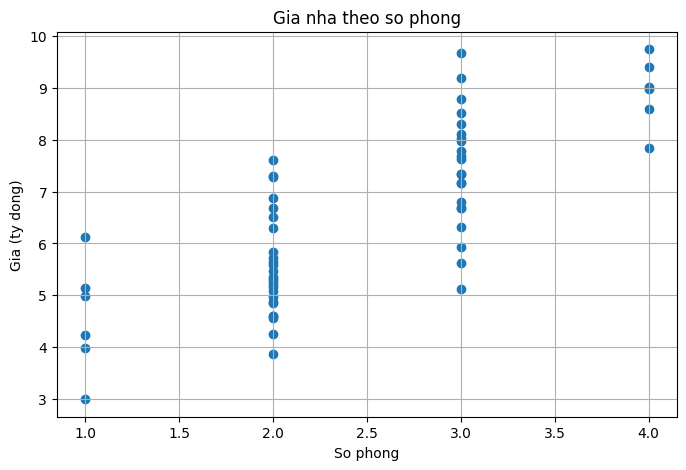

Nhan xet: Gia nha co xu huong tang khi so phong tang, tuy nhien cac diem khong nam hoan toan tren mot duong thang.


In [36]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/gia_nha.csv")

plt.figure(figsize=(8, 5))

plt.scatter(df["so_phong"], df["gia"])

plt.xlabel("So phong")
plt.ylabel("Gia (ty dong)")
plt.title("Gia nha theo so phong")

plt.grid(True)

plt.savefig("bai2.png", dpi=150)

plt.show()

print("Nhan xet: Gia nha co xu huong tang khi so phong tang, tuy nhien cac diem khong nam hoan toan tren mot duong thang.")

In [37]:
import pandas as pd

df = pd.read_csv("/content/gia_nha.csv")

x = df["tuoi_nha"].to_numpy()
y = df["gia"].to_numpy()

x_tb = x.mean()
y_tb = y.mean()

tu = ((x - x_tb) * (y - y_tb)).sum()
mau = ((x - x_tb) ** 2).sum()

w = tu / mau
b = y_tb - w * x_tb

print(f"w = {w:.6f}")
print(f"b = {b:.6f}")

if w < 0:
    print("Nhan xet: w mang dau am, cho thay khi tuoi nha tang thi gia du doan co xu huong giam.")
elif w > 0:
    print("Nhan xet: w mang dau duong, cho thay khi tuoi nha tang thi gia du doan co xu huong tang.")
else:
    print("Nhan xet: w bang 0, tuoi nha khong tao ra xu huong tuyen tinh ve gia.")

w = -0.037858
b = 6.983593
Nhan xet: w mang dau am, cho thay khi tuoi nha tang thi gia du doan co xu huong giam.


In [38]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("/content/gia_nha.csv")

X = df[["dien_tich", "so_phong"]]
y = df["gia"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)

y_pred = mo_hinh.predict(X_test)

r2 = r2_score(y_test, y_pred)

print(f"R2 tren tap kiem tra = {r2:.4f}")

if r2 > 0.9622:
    print("Nhan xet: Them bien so_phong lam R2 tang so voi mo hinh mot bien.")
else:
    print("Nhan xet: Them bien so_phong khong lam R2 tang so voi mo hinh mot bien.")

R2 tren tap kiem tra = 0.9698
Nhan xet: Them bien so_phong lam R2 tang so voi mo hinh mot bien.


In [39]:
import numpy as np
import pandas as pd

df = pd.read_csv("/content/gia_nha.csv")

x_goc = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

x_tb = x_goc.mean()
x_do_lech = x_goc.std()
x = (x_goc - x_tb) / x_do_lech

w, b = 0.0, 0.0

toc_do_hoc = 0.001
so_vong = 200
n = len(x)

for vong in range(1, so_vong + 1):
    y_du_doan = w * x + b

    chenh_lech = y_du_doan - y

    grad_w = (2 / n) * (chenh_lech * x).sum()
    grad_b = (2 / n) * chenh_lech.sum()

    w -= toc_do_hoc * grad_w
    b -= toc_do_hoc * grad_b

    if vong == 200:
        mse = (((w * x + b) - y) ** 2).mean()
        print(f"Toc do hoc = {toc_do_hoc}")
        print(f"MSE tai vong 200 = {mse:.4f}")

Toc do hoc = 0.001
MSE tai vong 200 = 20.2175


In [42]:
import numpy as np
import pandas as pd

df = pd.read_csv("/content/gia_nha.csv")

x_goc = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

x_tb = x_goc.mean()
x_do_lech = x_goc.std()
x = (x_goc - x_tb) / x_do_lech

w, b = 0.0, 0.0

toc_do_hoc = 1.06
so_vong = 200
n = len(x)

for vong in range(1, so_vong + 1):
    y_du_doan = w * x + b

    chenh_lech = y_du_doan - y

    grad_w = (2 / n) * (chenh_lech * x).sum()
    grad_b = (2 / n) * chenh_lech.sum()

    w -= toc_do_hoc * grad_w
    b -= toc_do_hoc * grad_b

    if vong == 200:
        mse = (((w * x + b) - y) ** 2).mean()
        print(f"Toc do hoc = {toc_do_hoc}")
        print(f"MSE tai vong 200 = {mse:.4f}")

Toc do hoc = 1.06
MSE tai vong 200 = 2171989243431779565568.0000


In [43]:
def du_doan_gia(dien_tich):
    w = 0.078367
    b = 0.401752

    if dien_tich < 35.5 or dien_tich > 117.5:
        print("Canh bao: Dien tich nam ngoai khoang du lieu 35.5 - 117.5 m2.")

    gia_du_doan = w * dien_tich + b

    return gia_du_doan


gia_60 = du_doan_gia(60)
print(f"Gia du doan cho 60 m2: {gia_60:.3f} ty dong")

gia_80 = du_doan_gia(80)
print(f"Gia du doan cho 80 m2: {gia_80:.3f} ty dong")

gia_200 = du_doan_gia(200)
print(f"Gia du doan cho 200 m2: {gia_200:.3f} ty dong")

Gia du doan cho 60 m2: 5.104 ty dong
Gia du doan cho 80 m2: 6.671 ty dong
Canh bao: Dien tich nam ngoai khoang du lieu 35.5 - 117.5 m2.
Gia du doan cho 200 m2: 16.075 ty dong
